<a href="https://colab.research.google.com/github/Chlo3Cook/spike-simulator-MAC/blob/main/spike_model_search_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spike data: find the best generative model

**Goal.** Pretend we only have the first 10 s of a recording. Build a model that can generate more data that looks like the real data (and can also continue it past 10 s).

**Idea.** The signal is a sum of three parts:

`signal(t) = drift(t) + spikes(t) + noise(t)`

For each part we have several candidate models. The notebook tries **every combination** and scores each one against the real data in two experiments:

* **Experiment A (forecast):** fit on the first 7 s, then check how well the model matches the real last 3 s.
* **Experiment B (reproduce):** fit on all 10 s, then check how well the model matches the whole 10 s.

Before any model search, section 4 **looks at the data** and tests simple physical explanations (a sine-wave drift, one fixed spike shape, white noise, Poisson spike times). The candidate list then includes those simple models next to flexible ones, and each part is also scored on its own with measures that fit that part (section 12). The winners are refitted on all 10 s. The final output is a formula and a function `generate_signal()` that makes new realistic data.

Run the cells from top to bottom. The full run takes a few minutes.

## 1. Imports and settings

Loads the libraries and puts every setting that can be changed in one place.
The detector settings (k = 8, 6 ms dead time, 101 ms baseline window) are the ones chosen in Assignment 2A, so the real data and the generated data are always analysed in exactly the same way.
`N_SIM` is how many random signals are generated for each combination (more = steadier scores but slower).

In [ ]:
import os, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from scipy import stats, optimize, signal as sps
from scipy.ndimage import median_filter
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
warnings.filterwarnings("ignore")

FS = 1000.0            # sampling rate in Hz (1 ms samples)
K_THR = 8.0            # threshold = K_THR * robust sigma
DEAD_MS = 6            # dead time of the detector (ms)
PEAK_MS = 5            # look for the peak this long after a crossing (ms)
BASE_WIN = 101         # running-median window (ms) used as baseline
PRE, POST = 3, 12      # spike template: samples before / after the peak

N_SIM = 8              # random signals generated per combination
SEED = 0
RUN_STABILITY = True   # re-run experiment A with other seeds to see if the winner changes
STABILITY_SEEDS = [11, 22]

# weight of each score in the final ranking (all equal by default)
WEIGHTS = dict(m_rate=1, m_isi=1, m_amp=1, m_sigma=1, m_acf=1, m_drift=1, m_w1=1)

## 2. Load the data

If you are in Colab, a file picker opens: choose `spike_data.npz` (it must contain `t` and `raw_data`).
If the file is already next to the notebook it is used directly.

In [ ]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_PATH = "/content/drive/MyDrive/python/spike_data (2).npz"
if not os.path.exists(DATA_PATH):
    if IN_COLAB:
        up = files.upload()
        DATA_PATH = list(up.keys())[0]
    else:
        raise FileNotFoundError("Put spike_data.npz next to this notebook.")

d = np.load(DATA_PATH, allow_pickle=False)
t_all, raw = d["t"], d["raw_data"].astype(float)
assert len(t_all) == len(raw) == 10000 and np.allclose(np.diff(t_all), 1/FS)
print(f"{len(raw)} samples, {len(raw)/FS:.1f} s, fs = {FS:.0f} Hz")

Saving spike_data (2).npz to spike_data (2) (1).npz
10000 samples, 10.0 s, fs = 1000 Hz


## 3. The detector (same as Assignment 2A/2B)

Every comparison runs the **same** detector on the real data and on generated data, so any difference comes from the data and not from the analysis.

Steps: subtract a 101 ms running median (the slow baseline) → estimate noise with the MAD → threshold at 8 sigma → one event per upward crossing (6 ms dead time) → peak = maximum within 5 ms after the crossing.
The running median uses a shrinking window at the two ends so a spike at the very start or end is not absorbed into its own baseline.

In [ ]:
def running_median(x, window=BASE_WIN):
    base = median_filter(x, size=window, mode="nearest")
    h, n = window // 2, len(x)
    for i in range(min(h, n)):                       # shrinking window at both ends
        base[i] = np.median(x[:i + h + 1])
        j = n - 1 - i
        base[j] = np.median(x[max(0, j - h):])
    return base

def robust_sigma(y):
    return np.median(np.abs(y - np.median(y))) / 0.6745

def detect(x, k=K_THR, dead_ms=DEAD_MS, peak_ms=PEAK_MS):
    base = running_median(x)
    y = x - base
    sigma = robust_sigma(y)
    above = y > k * sigma
    prev = np.concatenate(([False], above[:-1]))
    cross = np.flatnonzero(above & ~prev)            # start of each above-threshold run
    dead = int(round(dead_ms * FS / 1000)); pk = int(round(peak_ms * FS / 1000))
    kept, last = [], -10**9
    for c in cross:                                  # dead time
        if c - last > dead:
            kept.append(c); last = c
    cross = np.array(kept, dtype=int)
    peaks = np.array([c + int(np.argmax(y[c:c + pk + 1])) for c in cross], dtype=int)
    return dict(base=base, y=y, sigma=sigma, cross=cross, peaks=peaks)

real_det = detect(raw)
print("real data: spikes =", len(real_det["cross"]), "| rate =", len(real_det["cross"]) / (len(raw)/FS), "Hz | sigma =", round(real_det["sigma"], 3))

real data: spikes = 42 | rate = 4.2 Hz | sigma = 0.307


## 3b. Look at the data first (what is the signal really made of?)

Before comparing models, test simple explanations directly on the data:

1. **Spike shape.** Average all spikes aligned on their first sample and fit `A * exp(-t/tau)`.
2. **Do spike heights really vary?** If the spread of the first-sample height is about the same as the noise level, the spikes all have the same true height and the spread is only noise.
3. **Drift.** Fit one sine wave (free frequency) together with the spikes, directly on the raw data. Then fit the first 7 s only and see how well it predicts the baseline in the last 3 s.
4. **Noise.** What is left after removing the sine and the spikes: is it normal and uncorrelated?
5. **Spike times.** Compare the gaps between spikes with a Poisson process (gap variability CV close to 1, counts per second with variance close to the mean).

In [ ]:
n = len(raw); tt_all = np.arange(n) / FS
cr = real_det["cross"]; ydet = real_det["y"]
print("first-sample == peak for", int(np.sum(cr == real_det["peaks"])), "of", len(cr), "spikes")

# 1) shape
Wn = np.array([ydet[c:c+12] for c in cr if c + 12 < n]); mean_shape = Wn.mean(0)
(A_fit, tau_fit), _ = optimize.curve_fit(lambda k, A, tau: A * np.exp(-k / tau), np.arange(12), mean_shape, p0=[5, 3])
print(f"1) spike shape ~ A*exp(-t/tau): A = {A_fit:.2f}, tau = {tau_fit:.2f} ms | max misfit {np.abs(mean_shape - A_fit*np.exp(-np.arange(12)/tau_fit)).max():.2f}")

# 2) heights
print(f"2) spread of the first-sample height = {Wn[:,0].std():.3f}  vs  noise sigma = {real_det['sigma']:.3f}  -> spikes have the SAME height; the spread is noise")

# 3) drift: one sine + spikes, joint least squares on the raw data
def spike_train(tau, onsets, n_=n):
    s_ = np.zeros(n_)
    for c in onsets:
        L = min(60, n_ - c); s_[c:c+L] += np.exp(-np.arange(L) / tau)
    return s_
def joint_fit(tr_end):
    def design(par):
        return np.column_stack([np.ones(n), np.sin(2*np.pi*par[0]*tt_all), np.cos(2*np.pi*par[0]*tt_all), spike_train(par[1], cr)])
    def sse(par):
        X = design(par)[:tr_end]; co = np.linalg.lstsq(X, raw[:tr_end], rcond=None)[0]; r = raw[:tr_end] - X @ co; return r @ r
    best = min((optimize.minimize(sse, [f0, 3.0], method="Nelder-Mead") for f0 in (0.08, 0.09, 0.1)), key=lambda r: r.fun)
    X = design(best.x); return best.x, np.linalg.lstsq(X[:tr_end], raw[:tr_end], rcond=None)[0], X
par, co, X = joint_fit(n); res = raw - X @ co
print(f"3) drift = {co[0]:.3f} + {np.hypot(co[1], co[2]):.3f}*sin(2*pi*{par[0]:.4f}*t + {np.arctan2(co[2], co[1]):.2f})   (period {1/par[0]:.1f} s) | spike height A = {co[3]:.2f}, tau = {par[1]:.2f} ms")
par7, co7, X7 = joint_fit(7000)
err = np.sqrt(np.mean((X7[7000:, :3] @ co7[:3] - real_det["base"][7000:])**2))
print(f"   fitted on 0-7 s only, predicting the baseline for 7-10 s: RMSE = {err:.3f}   (baseline spread {real_det['base'].std():.3f})")

# 4) noise
print(f"4) noise left over: sd = {res.std():.3f}, skew = {stats.skew(res):.2f}, excess kurtosis = {stats.kurtosis(res):.2f}, normality p = {stats.normaltest(res).pvalue:.2f}, autocorrelation lags 1-3 = {np.round([np.corrcoef(res[:-k], res[k:])[0,1] for k in (1,2,3)], 3)}")

# 5) timing
isi_ = np.diff(cr) / FS; c1 = np.histogram(cr / FS, bins=np.arange(0, 10.01, 1))[0]
N_ = len(cr); lo_, hi_ = stats.chi2.ppf([0.025, 0.975], [2*N_, 2*N_ + 2]) / 2 / 10
print(f"5) spike gaps: CV = {isi_.std()/isi_.mean():.2f} (Poisson = 1) | spikes per second: mean {c1.mean():.1f}, variance {c1.var():.1f} (Poisson: equal)")
print(f"   rate = {N_/10:.1f} Hz, 95% interval {lo_:.1f} to {hi_:.1f} Hz.  Poisson counts vary by about +-{np.sqrt(N_):.1f} spikes in 10 s, so 42 vs 47 is a normal draw")

first-sample == peak for 42 of 42 spikes
1) spike shape ~ A*exp(-t/tau): A = 4.96, tau = 2.86 ms | max misfit 0.11
2) spread of the first-sample height = 0.286  vs  noise sigma = 0.307  -> spikes have the SAME height; the spread is noise
3) drift = 0.003 + 0.647*sin(2*pi*0.0908*t + 0.29)   (period 11.0 s) | spike height A = 5.02, tau = 2.98 ms
   fitted on 0-7 s only, predicting the baseline for 7-10 s: RMSE = 0.047   (baseline spread 0.486)
4) noise left over: sd = 0.298, skew = 0.02, excess kurtosis = -0.04, normality p = 0.49, autocorrelation lags 1-3 = [-0.02  -0.004 -0.02 ]
5) spike gaps: CV = 1.07 (Poisson = 1) | spikes per second: mean 4.2, variance 4.8 (Poisson: equal)
   rate = 4.2 Hz, 95% interval 3.0 to 5.7 Hz.  Poisson counts vary by about +-6.5 spikes in 10 s, so 42 vs 47 is a normal draw


## 4. Split the data into its three parts

Given a recording (or part of it) this step measures everything the models need:

* **baseline** (drift): the running median.
* **spikes**: peak heights, ISIs (time between spikes) and the average spike shape. The shape is made by aligning every spike on its peak and averaging (each spike divided by its own peak height, so the template peaks at 1).
* **noise**: what is left after the baseline and the scaled spike template are removed.

Models are always fitted only on the training part, so the test part stays unseen.

In [ ]:
def decompose(x):
    det = detect(x)
    y, pk = det["y"], det["peaks"]
    ok = pk[(pk - PRE >= 0) & (pk + POST < len(y))]
    wins = np.array([y[p - PRE:p + POST + 1] for p in ok])         # raw spike windows
    amps = y[ok]
    template = wins.mean(axis=0) / wins[:, PRE].mean()              # shape, peak = 1
    resid = y.copy()
    for p, a in zip(ok, amps):                                      # remove spikes -> noise
        resid[p - PRE:p + POST + 1] -= a * template
    return dict(det=det, base=det["base"], y=y, amps=amps, wins=wins, template=template,
                resid=resid, isi=np.diff(det["cross"]) / FS, n_spk=len(det["cross"]),
                dur=len(x) / FS, sigma=robust_sigma(resid))

full = decompose(raw)
print("template (peak=1):", np.round(full["template"], 2))
print("peak heights: mean %.2f, sd %.2f | ISI: min %.0f ms, median %.0f ms | noise sigma %.3f"
      % (full["amps"].mean(), full["amps"].std(), full["isi"].min()*1000, np.median(full["isi"])*1000, full["sigma"]))

template (peak=1): [-0.02 -0.03 -0.02  1.    0.7   0.5   0.37  0.23  0.18  0.12  0.08  0.05
  0.04  0.01  0.04  0.01]
peak heights: mean 4.95, sd 0.29 | ISI: min 11 ms, median 169 ms | noise sigma 0.293


## 5. Candidate models for the DRIFT (5 options)

The drift is slow, so the question is how to continue it past the training data. Each model is fitted to the baseline of the training data and can then be evaluated at any time.

| name | idea | good if | risk |
|---|---|---|---|
| `sin1` | mean + ONE sine wave (frequency found automatically) | drift is a single slow oscillation | wrong if the drift is not periodic |
| `sin2` | mean + 2 sine waves | two oscillations | the 2nd wave can just fit noise |
| `poly3` | cubic polynomial | drift is a simple smooth curve | explodes outside the fitted range |
| `gp` | Gaussian process (smooth kernel), random draws from its posterior | unknown smooth shape, gives honest uncertainty | past the data it forgets the shape and wanders around the mean |
| `ou` | Ornstein-Uhlenbeck: random wander that is pulled back to a mean | only the statistics matter, not the exact path | does not follow the observed path at all |

In [ ]:
def fit_drift(name, t, b):
    if name == "poly3":
        co = np.polyfit(t / 10, b, 3)
        return dict(name=name, params=dict(coef=co.tolist()),
                    sample=lambda tq, rng: np.polyval(co, tq / 10),
                    formula="drift(t) = " + " + ".join(f"{c:.4g}*(t/10)^{3-i}" for i, c in enumerate(co)))
    if name in ("sin1", "sin2"):
        K = int(name[-1]); tt, bb = t[::10], b[::10]
        freqs = np.arange(0.05, 3.0, 0.01); chosen = []; res = bb - bb.mean()
        for _ in range(K):                                   # greedy: add the best-fitting frequency one at a time
            best = (np.inf, None, None)
            for f in freqs:
                A = np.c_[np.sin(2*np.pi*f*tt), np.cos(2*np.pi*f*tt)]
                co, *_ = np.linalg.lstsq(A, res, rcond=None)
                sse = np.sum((res - A @ co)**2)
                if sse < best[0]: best = (sse, f, A @ co)
            chosen.append(best[1]); res = res - best[2]
        design = lambda tq, fr: np.column_stack([np.ones(len(tq))] + [g(2*np.pi*f*tq) for f in fr for g in (np.sin, np.cos)])
        def sse_f(fr):
            co = np.linalg.lstsq(design(tt, fr), bb, rcond=None)[0]; r = bb - design(tt, fr) @ co; return r @ r
        chosen = list(optimize.minimize(sse_f, chosen, method="Nelder-Mead", options=dict(xatol=1e-5, fatol=1e-10)).x)   # fine-tune frequencies
        co, *_ = np.linalg.lstsq(design(tt, chosen), bb, rcond=None)
        terms = " + ".join(f"{np.hypot(co[1+2*i], co[2+2*i]):.3g}*sin(2*pi*{f:.4f}*t + {np.arctan2(co[2+2*i], co[1+2*i]):.2f})" for i, f in enumerate(chosen))
        return dict(name=name, params=dict(freqs=[float(f) for f in chosen], coef=co.tolist()),
                    sample=lambda tq, rng: design(tq, chosen) @ co,
                    formula=f"drift(t) = {co[0]:.3g} + {terms}   (period {1/chosen[0]:.1f} s)")
    if name == "gp":
        tt, bb = t[::50], b[::50]; mu, sd = bb.mean(), bb.std()
        ker = C(1.0, (1e-2, 1e2)) * RBF(1.0, (0.2, 20)) + WhiteKernel(1e-2, (1e-6, 1))
        gp = GPR(ker, n_restarts_optimizer=2, random_state=0).fit(tt[:, None], (bb - mu) / sd)
        k1, noise = gp.kernel_.k1, gp.kernel_.k2.noise_level
        Kinv = np.linalg.inv(k1(tt[:, None]) + noise * np.eye(len(tt))); alpha = Kinv @ ((bb - mu) / sd)
        def sample(tq, rng):
            g = np.arange(0, tq[-1] + 0.05, 0.05)[:, None]
            Ks = k1(g, tt[:, None]); mean = Ks @ alpha
            cov = k1(g) - Ks @ Kinv @ Ks.T
            for jit in (1e-8, 1e-6, 1e-4, 1e-2):
                try: L = np.linalg.cholesky(cov + jit * np.eye(len(g))); break
                except np.linalg.LinAlgError: continue
            s = (mean + L @ rng.standard_normal(len(g))) * sd + mu
            return np.interp(tq, g[:, 0], s)
        amp, ls = float(np.sqrt(k1.k1.constant_value)), float(k1.k2.length_scale)
        return dict(name=name, params=dict(mean=float(mu), scale=float(sd), amp=amp, length_scale=ls, noise=float(noise)),
                    sample=sample,
                    formula=f"drift(t) ~ GaussianProcess(mean = data, kernel = {amp**2:.3g} * exp(-(t-t')^2 / (2*{ls:.2f}^2))), conditioned on the observed baseline")
    if name == "ou":
        dt = 0.05; bb = b[::50]; mu, sd = bb.mean(), bb.std()
        phi = float(np.clip(np.corrcoef(bb[:-1], bb[1:])[0, 1], 0.01, 0.9999))
        def sample(tq, rng):
            g = np.arange(0, tq[-1] + dt, dt); x = np.empty(len(g)); x[0] = rng.normal(mu, sd)
            e = rng.standard_normal(len(g)) * sd * np.sqrt(1 - phi**2)
            for i in range(1, len(g)): x[i] = mu + phi * (x[i-1] - mu) + e[i]
            return np.interp(tq, g, x)
        return dict(name=name, params=dict(mean=float(mu), sd=float(sd), phi_50ms=phi),
                    sample=sample,
                    formula=f"drift(t): Ornstein-Uhlenbeck, mean {mu:.3g}, stationary sd {sd:.3g}, correlation time {-dt/np.log(phi):.2f} s")
    raise ValueError(name)

DRIFT_NAMES = ["sin1", "sin2", "poly3", "gp", "ou"]
tmp = {n: fit_drift(n, np.arange(len(raw))/FS, full["base"]) for n in DRIFT_NAMES}
for n, m in tmp.items(): print(n, "->", m["formula"][:150])

sin1 -> drift(t) = 0.0223 + 0.651*sin(2*pi*0.0899*t + 0.32)   (period 11.1 s)
sin2 -> drift(t) = 0.0225 + 0.651*sin(2*pi*0.0899*t + 0.32) + 0.0218*sin(2*pi*2.7260*t + -2.84)   (period 11.1 s)
poly3 -> drift(t) = 12.27*(t/10)^3 + -18.42*(t/10)^2 + 5.909*(t/10)^1 + 0.1397*(t/10)^0
gp -> drift(t) ~ GaussianProcess(mean = data, kernel = 1.4 * exp(-(t-t')^2 / (2*3.04^2))), conditioned on the observed baseline
ou -> drift(t): Ornstein-Uhlenbeck, mean 0.0234, stationary sd 0.487, correlation time 8.34 s


## 6. Candidate models for the NOISE (5 options)

Noise is what remains after the drift and spikes are removed. The models differ in whether neighbouring samples are correlated and whether the tails are heavier than a normal distribution. All of them use the noise level measured from the training data.

| name | idea |
|---|---|
| `white` | independent normal noise |
| `ar1` | normal noise where each sample depends on the previous one |
| `ar2` | same with the previous two samples |
| `student` | independent noise with heavier tails (Student-t) |
| `bootstrap` | pieces (50 samples) of the real noise copied at random, no distribution assumed |

In [ ]:
def acf(x, nlag):
    x = x - x.mean()
    return np.array([np.sum(x[:len(x)-k] * x[k:]) for k in range(nlag + 1)]) / np.sum(x * x)

def fit_noise(name, dec):
    r, s = dec["resid"], dec["sigma"]
    if name == "white":
        return dict(name=name, params=dict(sigma=float(s)), sample=lambda n, rng: rng.normal(0, s, n),
                    formula=f"noise ~ Normal(0, {s:.3f}^2), independent samples")
    if name in ("ar1", "ar2"):
        p = int(name[-1]); rho = acf(r, p)
        phi = np.linalg.solve(np.array([[rho[abs(i-j)] for j in range(p)] for i in range(p)]), rho[1:p+1])
        innov = s * np.sqrt(max(1 - phi @ rho[1:p+1], 1e-6))
        def sample(n, rng):
            e = rng.normal(0, innov, n + 500)
            return sps.lfilter([1.0], np.r_[1.0, -phi], e)[500:]
        terms = " + ".join(f"{c:.3f}*n[i-{j+1}]" for j, c in enumerate(phi))
        return dict(name=name, params=dict(phi=phi.tolist(), innov_sd=float(innov), sigma=float(s)), sample=sample,
                    formula=f"noise: n[i] = {terms} + e[i],  e ~ Normal(0, {innov:.3f}^2)")
    if name == "student":
        df, loc, sc = stats.t.fit(r); df = float(np.clip(df, 2.5, 200))
        return dict(name=name, params=dict(df=df, loc=float(loc), scale=float(sc)),
                    sample=lambda n, rng: rng.standard_t(df, n) * sc + loc,
                    formula=f"noise ~ Student-t(df={df:.1f}, loc={loc:.3f}, scale={sc:.3f}), independent samples")
    if name == "bootstrap":
        B = 50
        def sample(n, rng):
            starts = rng.integers(0, len(r) - B, size=n // B + 1)
            return np.concatenate([r[i:i+B] for i in starts])[:n]
        return dict(name=name, params=dict(block=B), sample=sample,
                    formula=f"noise: random {B}-sample blocks copied from the observed noise")
    raise ValueError(name)

NOISE_NAMES = ["white", "ar1", "ar2", "student", "bootstrap"]
print("noise autocorrelation lags 1-3 (real):", np.round(acf(full["resid"], 3)[1:], 3))
print("noise skew %.2f, excess kurtosis %.2f" % (stats.skew(full["resid"]), stats.kurtosis(full["resid"])))

noise autocorrelation lags 1-3 (real): [-0.009  0.006 -0.01 ]
noise skew 0.03, excess kurtosis 0.00


## 7. Candidate models for the SPIKE SHAPE and HEIGHT (4 options)

Each spike is drawn as `height x shape`, placed at the spike times. Whether spike heights really differ is checked in section 3b.

| name | idea |
|---|---|
| `exp_fixed` | every spike is exactly `A*exp(-t/tau)` (A and tau fitted), same height for all |
| `template_fixed` | every spike has the average shape (as a table of numbers) and the average height |
| `template_jitter` | average shape, but the height varies like the real heights (normal distribution) |
| `resample` | each generated spike is a copy of one randomly chosen real spike |

In [ ]:
def fit_shape(name, dec):
    tmpl, amps, wins = dec["template"], dec["amps"], dec["wins"]
    mu, sd = amps.mean(), amps.std()
    def put(sig, start, w):
        lo, hi = max(start, 0), min(start + len(w), len(sig))
        if hi > lo: sig[lo:hi] += w[lo - start: hi - start]

    if name in ("template_fixed", "template_jitter"):
        jit = name == "template_jitter"
        def render(times, n, rng):
            s = np.zeros(n)
            for tt in times:
                a = max(rng.normal(mu, sd), 0.5 * mu) if jit else mu
                put(s, int(round(tt * FS)) - PRE, a * tmpl)
            return s
        return dict(name=name, params=dict(template=tmpl.tolist(), amp_mean=float(mu), amp_sd=float(sd if jit else 0)),
                    render=render,
                    formula=f"spike(t) = A * template[t - t_i], template = {np.round(tmpl, 2).tolist()} (peak at index {PRE}), A ~ " +
                            (f"Normal({mu:.2f}, {sd:.2f}^2)" if jit else f"{mu:.2f} (fixed)"))
    if name == "exp_fixed":
        # every spike is exactly A*exp(-t/tau): fixed height, shape fitted to the average spike from the first sample
        W0 = np.array([dec["y"][p:p+12] for p in dec["det"]["peaks"] if p + 12 < len(dec["y"])]).mean(0)
        (A0, tau0), _ = optimize.curve_fit(lambda k, A, tau: A * np.exp(-k / tau), np.arange(12), W0, p0=[5, 3])
        w = A0 * np.exp(-np.arange(60) / tau0)
        def render(times, n, rng):
            s = np.zeros(n)
            for tt in times: put(s, int(round(tt * FS)), w)
            return s
        return dict(name=name, params=dict(A=float(A0), tau_ms=float(tau0)), render=render,
                    formula=f"spike(t) = {A0:.2f} * exp(-(t - t_i)/{tau0:.2f} ms) for t >= t_i, else 0   (same height for every spike)")
    if name == "resample":
        def render(times, n, rng):
            s = np.zeros(n)
            for tt in times:
                put(s, int(round(tt * FS)) - PRE, wins[rng.integers(len(wins))])
            return s
        return dict(name=name, params=dict(n_spikes=int(len(wins))), render=render,
                    formula=f"spike(t): copy of one of the {len(wins)} observed spikes, chosen at random")
    raise ValueError(name)

SHAPE_NAMES = ["exp_fixed", "template_fixed", "template_jitter", "resample"]

## 8. Candidate models for the SPIKE TIMES (7 options)

The spike times are produced by drawing the gap between spikes (the ISI) again and again (a renewal process), except `poisson_n`. The models differ in how the ISI is distributed. This part decides the firing rate and how bursty the spikes are.

| name | idea |
|---|---|
| `poisson` | exponential ISIs (completely random, no memory) |
| `poisson_n` | same Poisson process, but the **number** of spikes is fixed to rate x duration (e.g. exactly 42 in 10 s) and they are placed uniformly at random. This removes the +-6 spike count scatter of a plain Poisson process |
| `poisson_n_gap` | same as `poisson_n`, plus a minimum gap between spikes (the data has no gaps shorter than 11 ms). With this the generated spike count is exactly rate x duration, and the detector never merges two generated spikes |
| `dead_poisson` | exponential ISIs plus a minimum gap (refractory period), count not fixed |
| `gamma` | gamma-distributed ISIs (can be more regular or more bursty than Poisson) |
| `lognormal` | log-normal ISIs (long tail of long gaps, typical for bursting cells) |
| `bootstrap` | ISIs copied at random from the observed ones |

`scale` multiplies all gaps, so the rate can be changed later (scale 2 = half the rate).

In [ ]:
def renewal(draw, T, rng, scale=1.0):
    isi = draw(max(60, int(T * 12)), rng) * scale
    t = isi[0] * rng.random() + np.concatenate(([0.0], np.cumsum(isi[1:])))
    while t[-1] < T:
        more = draw(60, rng) * scale
        t = np.concatenate((t, t[-1] + np.cumsum(more)))
    return t[t < T]

def fit_timing(name, dec):
    isi = dec["isi"]; m = isi.mean(); rate = dec["n_spk"] / dec["dur"]
    if name == "poisson":
        draw = lambda k, rng: rng.exponential(m, k); form = f"ISI ~ Exponential(mean {m*1000:.0f} ms)  (Poisson process, rate {rate:.2f} Hz)"; par = dict(mean=float(m))
        lp = lambda x: stats.expon.logpdf(x, scale=m)
    elif name == "poisson_n":                       # Poisson process with the number of spikes fixed to rate*T
        par = dict(rate=float(rate)); form = f"exactly round({rate:.2f} * duration) spikes, placed uniformly at random (a Poisson process with its count fixed)"
        def sample(T, rng, scale=1.0):
            return np.sort(rng.uniform(0, T, int(round(rate / scale * T))))
        return dict(name=name, params=par, rate=float(rate), sample=sample, formula=form, logpdf=lambda x: stats.expon.logpdf(x, scale=m))
    elif name == "poisson_n_gap":                   # fixed count + minimum gap between spikes
        dd = 0.9 * isi.min(); ex = max(m - dd, 1e-3); N0 = rate
        par = dict(rate=float(rate), min_gap=float(dd))
        form = (f"exactly round({rate:.2f} * duration) spikes placed uniformly at random, at least {dd*1000:.1f} ms apart "
                f"(shortest observed gap is {isi.min()*1000:.0f} ms)")
        def sample(T, rng, scale=1.0):
            N = int(round(N0 / scale * T)); span = max(T - (N - 1) * dd, 1e-6)
            return np.sort(rng.uniform(0, span, N)) + dd * np.arange(N)      # uniform order statistics, then spread by the minimum gap
        return dict(name=name, params=par, rate=float(rate), sample=sample, formula=form,
                    logpdf=lambda x: np.where(x > dd, stats.expon.logpdf(np.maximum(x - dd, 1e-9), scale=ex), -20.0))
    elif name == "dead_poisson":
        dd = 0.9 * isi.min(); ex = max(m - dd, 1e-3)
        draw = lambda k, rng: dd + rng.exponential(ex, k); par = dict(dead=float(dd), mean_excess=float(ex))
        form = f"ISI = {dd*1000:.1f} ms + Exponential(mean {ex*1000:.0f} ms)"
        lp = lambda x: np.where(x > dd, stats.expon.logpdf(np.maximum(x - dd, 1e-9), scale=ex), -20.0)
    elif name == "gamma":
        a, _, sc = stats.gamma.fit(isi, floc=0)
        draw = lambda k, rng: rng.gamma(a, sc, k); par = dict(shape=float(a), scale=float(sc))
        form = f"ISI ~ Gamma(shape {a:.2f}, scale {sc*1000:.0f} ms)"
        lp = lambda x: stats.gamma.logpdf(x, a, scale=sc)
    elif name == "lognormal":
        s_, _, sc = stats.lognorm.fit(isi, floc=0)
        draw = lambda k, rng: rng.lognormal(np.log(sc), s_, k); par = dict(sigma=float(s_), scale=float(sc))
        form = f"ISI ~ LogNormal(median {sc*1000:.0f} ms, sigma {s_:.2f})"
        lp = lambda x: stats.lognorm.logpdf(x, s_, scale=sc)
    elif name == "bootstrap":
        kde = stats.gaussian_kde(isi)
        draw = lambda k, rng: rng.choice(isi, k); par = dict(n_isi=int(len(isi))); form = f"ISI: random draws from the {len(isi)} observed ISIs"
        lp = lambda x: np.log(np.maximum(kde(x), 1e-12))
    else: raise ValueError(name)
    return dict(name=name, params=par, rate=float(rate), sample=lambda T, rng, scale=1.0: renewal(draw, T, rng, scale), formula=form, logpdf=lp)

TIMING_NAMES = ["poisson", "poisson_n", "poisson_n_gap", "dead_poisson", "gamma", "lognormal", "bootstrap"]
n_combo = len(DRIFT_NAMES) * len(NOISE_NAMES) * len(SHAPE_NAMES) * len(TIMING_NAMES)
print("number of combinations:", n_combo)

number of combinations: 700


## 9. Put a model together and generate a signal

`signal = drift + noise + spikes`. This function picks one candidate for each part and builds a signal of any length.

In [ ]:
def fit_all(x):
    dec = decompose(x); t = np.arange(len(x)) / FS
    return dict(dec=dec,
                drift={n: fit_drift(n, t, dec["base"]) for n in DRIFT_NAMES},
                noise={n: fit_noise(n, dec) for n in NOISE_NAMES},
                shape={n: fit_shape(n, dec) for n in SHAPE_NAMES},
                timing={n: fit_timing(n, dec) for n in TIMING_NAMES})

def generate(models, duration, rng, rate_scale=1.0, spike_times=None):
    n = int(round(duration * FS)); t = np.arange(n) / FS
    d = models["drift"]["sample"](t, rng)
    nz = models["noise"]["sample"](n, rng)
    times = models["timing"]["sample"](duration, rng, rate_scale) if spike_times is None else np.asarray(spike_times)
    sp = models["shape"]["render"](times, n, rng)
    return dict(t=t, raw=d + nz + sp, drift=d, noise=nz, spikes=sp, times=times)

## 10. Scores: how close is generated data to real data?

Generated signals are random, so we compare **statistics** over a time window, not sample by sample. Seven scores are computed (all are errors: **lower is better**):

| score | what it checks |
|---|---|
| `m_rate` | firing rate: relative difference between the average generated spike count and the real count |
| `m_isi` | spike timing: KS distance between generated and real ISI distributions |
| `m_amp` | spike heights: KS distance between generated and real peak heights |
| `m_sigma` | noise level: relative difference of the robust sigma |
| `m_acf` | noise correlation: average difference of the autocorrelation at lags 1 to 5 (spikes masked out) |
| `m_drift` | drift: RMS error between the generated drift and the real baseline, in units of the real baseline's spread |
| `m_w1` | overall amplitude distribution: Wasserstein distance between the sample values, in units of the real sigma |

Every generated signal goes through the same detector as the real data.

In [ ]:
def win_stats(det, w0, w1):
    y = det["y"]
    cr = det["cross"][(det["cross"] >= w0) & (det["cross"] < w1)]
    pk = det["peaks"][(det["peaks"] >= w0) & (det["peaks"] < w1)]
    yw = y[w0:w1]; valid = np.ones(len(yw), bool)
    for c in cr:
        valid[max(0, c - w0 - PRE): c - w0 + POST + 1] = False
    cs = []
    for k in range(0, 6):
        v = valid[:len(yw) - k] & valid[k:]
        cs.append(np.sum(yw[:len(yw)-k][v] * yw[k:][v]) / max(v.sum(), 1))
    ac = np.array(cs[1:]) / cs[0]
    return dict(n=len(cr), isi=np.diff(cr) / FS, amp=y[pk], sigma=robust_sigma(yw), acf=ac, y=yw)

def ks(a, b):
    return stats.ks_2samp(a, b).statistic if len(a) > 1 and len(b) > 1 else np.nan

def score_combo(real, sims, drift_err):
    n_real = max(real["n"], 1)
    return dict(
        m_rate=abs(np.mean([s["n"] for s in sims]) - real["n"]) / n_real,
        m_isi=ks(np.concatenate([s["isi"] for s in sims]), real["isi"]),
        m_amp=ks(np.concatenate([s["amp"] for s in sims]), real["amp"]),
        m_sigma=abs(np.mean([s["sigma"] for s in sims]) - real["sigma"]) / real["sigma"],
        m_acf=np.mean([np.mean(np.abs(s["acf"][:5] - real["acf"][:5])) for s in sims]),
        m_drift=drift_err,
        m_w1=np.mean([stats.wasserstein_distance(s["y"], real["y"]) for s in sims]) / real["sigma"])

## 11. Run one experiment (try every combination)

For a chosen training length and test window this function:

1. fits all candidate models on the training part only,
2. generates `N_SIM` random signals for each candidate (drift, noise and spikes are generated once and then added in every combination, which is faster than starting over each time),
3. adds them together for every combination (700), runs the detector and computes the seven scores,
4. ranks all combinations on each score and averages the ranks (weights from the settings). **Lower mean rank = better.**

Ranks are used instead of raw numbers so that scores with different units can be combined fairly.

In [ ]:
def run_experiment(train_s, win_s, seed, n_sim=N_SIM, label=""):
    t0 = time.time()
    n_tr = int(train_s * FS); w0, w1 = int(win_s[0] * FS), int(win_s[1] * FS)
    dur = len(raw) / FS                                  # always generate the full 10 s so the baseline can be estimated
    models = fit_all(raw[:n_tr])
    rng = np.random.default_rng(seed)
    n = len(raw); t = np.arange(n) / FS
    real = win_stats(real_det, w0, w1)
    base_real = real_det["base"]; spread = base_real.std()

    D = {k: [m["sample"](t, rng) for _ in range(n_sim)] for k, m in models["drift"].items()}
    N = {k: [m["sample"](n, rng) for _ in range(n_sim)] for k, m in models["noise"].items()}
    S = {}
    for tk, tm in models["timing"].items():
        for sk, sm in models["shape"].items():
            S[(tk, sk)] = [sm["render"](tm["sample"](dur, rng), n, rng) for _ in range(n_sim)]
    drift_err = {k: np.mean([np.sqrt(np.mean((d[w0:w1] - base_real[w0:w1])**2)) / spread for d in v]) for k, v in D.items()}

    rows = []
    for dk, nk, (tk, sk) in product(DRIFT_NAMES, NOISE_NAMES, S.keys()):
        sims = [win_stats(detect(D[dk][i] + N[nk][i] + S[(tk, sk)][i]), w0, w1) for i in range(n_sim)]
        rows.append(dict(drift=dk, noise=nk, shape=sk, timing=tk, **score_combo(real, sims, drift_err[dk])))
    df = pd.DataFrame(rows)
    ranks = df[list(WEIGHTS)].rank(method="average").fillna(len(df))
    df["mean_rank"] = sum(ranks[c] * w for c, w in WEIGHTS.items()) / sum(WEIGHTS.values())
    df = df.sort_values("mean_rank").reset_index(drop=True)
    print(f"{label}: {len(df)} combinations scored in {time.time()-t0:.0f} s")
    return df, models

KEYS = ["drift", "noise", "shape", "timing"]

## 12. Experiment A: train on 0-7 s, test on the unseen 7-10 s

This is the real test of the idea: the model has never seen the last 3 seconds. The table shows the 10 best combinations (lower scores are better).

Note: the last 3 s contain only about a dozen spikes, so `m_rate`, `m_isi` and `m_amp` are noisy. That is why section 15 repeats this experiment with other random seeds.

In [ ]:
dfA, modelsA = run_experiment(7.0, (7.0, 10.0), SEED, label="Experiment A (train 0-7 s, test 7-10 s)")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
dfA.head(10).round(3)

Experiment A (train 0-7 s, test 7-10 s): 700 combinations scored in 38 s


,drift,noise,shape,timing,m_rate,m_isi,m_amp,m_sigma,m_acf,m_drift,m_w1,mean_rank
0,sin1,ar2,resample,gamma,0.250,0.343,0.270,0.001,0.018,0.097,0.059,81.786
1,sin2,ar2,resample,gamma,0.250,0.343,0.270,0.000,0.018,0.121,0.059,95.500
2,sin1,ar2,resample,bootstrap,0.288,0.346,0.308,0.002,0.016,0.097,0.062,112.643
3,sin1,ar2,exp_fixed,poisson_n,0.188,0.307,0.289,0.010,0.017,0.097,0.057,116.214
4,gp,ar2,resample,gamma,0.250,0.343,0.270,0.000,0.018,0.476,0.059,120.643
5,sin1,ar2,resample,dead_poisson,0.300,0.302,0.287,0.006,0.016,0.097,0.067,125.000
6,sin2,ar2,resample,bootstrap,0.288,0.346,0.308,0.001,0.015,0.121,0.062,127.357
7,sin1,student,exp_fixed,poisson_n,0.188,0.307,0.300,0.006,0.019,0.097,0.056,128.429
8,poly3,ar2,resample,gamma,0.250,0.343,0.270,0.000,0.018,0.733,0.059,136.643
9,sin2,ar2,resample,dead_poisson,0.300,0.302,0.287,0.005,0.016,0.121,0.067,138.571


## 13. Experiment B: train on all 10 s, test on the same 10 s

Here the model is fitted on everything and has to reproduce the whole recording. This is not a forecast. It checks that the model really can generate data like the real data when it is allowed to see it all (a model that cannot do this is not usable as a generator).

In [ ]:
dfB, modelsB = run_experiment(10.0, (0.0, 10.0), SEED + 1, label="Experiment B (train 0-10 s, test 0-10 s)")
dfB.head(10).round(3)

Experiment B (train 0-10 s, test 0-10 s): 700 combinations scored in 85 s


,drift,noise,shape,timing,m_rate,m_isi,m_amp,m_sigma,m_acf,m_drift,m_w1,mean_rank
0,sin2,bootstrap,resample,poisson_n,0.012,0.091,0.148,0.006,0.009,0.096,0.020,117.071
1,sin2,bootstrap,resample,gamma,0.006,0.090,0.120,0.006,0.009,0.096,0.039,130.857
2,sin1,bootstrap,resample,poisson_n,0.012,0.091,0.148,0.006,0.009,0.101,0.020,136.929
3,sin2,student,exp_fixed,poisson_n,0.015,0.145,0.106,0.000,0.013,0.096,0.019,141.714
4,sin2,ar2,resample,poisson_n,0.012,0.091,0.133,0.010,0.013,0.096,0.025,148.286
5,sin2,bootstrap,template_jitter,poisson_n_gap,0.000,0.146,0.122,0.012,0.009,0.096,0.019,149.643
6,sin1,bootstrap,resample,gamma,0.006,0.090,0.117,0.006,0.009,0.101,0.039,150.286
7,sin1,student,exp_fixed,poisson_n,0.015,0.145,0.103,0.000,0.013,0.101,0.019,160.857
8,gp,bootstrap,resample,poisson_n,0.012,0.091,0.151,0.006,0.009,0.102,0.020,161.714
9,sin1,ar2,resample,poisson_n,0.012,0.091,0.135,0.010,0.013,0.101,0.026,167.500


## 14. Score every part on its own (this decides the winner)

The three parts are simply added together and are generated independently of each other. So the best model for each part can be judged on its own, with a measure that suits only that part. This is cleaner than the combined scores of all 700 combinations above, which mix in random luck from the other parts (for example, drift models get ranked partly by how many spikes happened to be generated).

| part | how each option is scored (on the test window) |
|---|---|
| drift | RMS error against the real baseline, divided by the baseline spread. **Lower is better** |
| noise | average of three ranks: KS distance to the real noise values, autocorrelation error (lags 1-5), noise-level error |
| spike shape | average of two ranks: error of the average spike waveform against the real one, and KS distance of the first-sample height (model noise added) |
| spike timing | held-out log-likelihood of the real spike gaps under the fitted model. **Higher is better** |

**Experiment A (unseen 7-10 s) decides.** Experiment B (all 10 s, the model has seen the data) is shown as a check, because flexible models always look good on data they were fitted to. (For example the `bootstrap` noise copies the real noise, so it looks perfect in B.)

**Simplicity rule.** Only 3 s of test data (about 10 spikes) is used, so small score differences are just measurement noise. For each part we therefore take the **simplest** option whose scores are within a stated tolerance of the best one (`TOL` below). For spike timing the tolerance is 2 log-likelihood units in total, the usual "clearly better" threshold. This stops us from choosing a complicated model because of a tiny, meaningless gain.

**Spike timing tie-break.** The timing models are statistically tied (the spikes look like a plain Poisson process, so no model can be shown to be better). Among the tied models we take the one whose generated spike count is closest to rate x duration, because the aim is data that is as close as possible to the real recording. A plain Poisson process has a natural scatter of about +-6 spikes in 10 s (42 vs 47 is a normal draw), which the fixed-count versions remove.

In [ ]:
def score_parts(models, win_s, seed, n_rep=40):
    rng = np.random.default_rng(seed)
    w0, w1 = int(win_s[0] * FS), int(win_s[1] * FS); n_w = w1 - w0
    base_real = real_det["base"][w0:w1]; spread = real_det["base"].std()
    Rn = full["resid"][w0:w1]; sig_r = robust_sigma(Rn); ac_r = acf(Rn, 5)[1:]
    out = {}
    # drift
    t = np.arange(len(raw)) / FS
    out["drift"] = pd.DataFrame({"rmse": {k: np.mean([np.sqrt(np.mean((m["sample"](t, rng)[w0:w1] - base_real) ** 2)) / spread for _ in range(5)])
                                          for k, m in models["drift"].items()}})
    # noise
    rows = {}
    for k, m in models["noise"].items():
        dr = [m["sample"](n_w, rng) for _ in range(n_rep)]
        rows[k] = dict(ks=np.mean([stats.ks_2samp(x, Rn).statistic for x in dr]),
                       acf_err=np.mean([np.mean(np.abs(acf(x, 5)[1:] - ac_r)) for x in dr]),
                       sigma_err=np.mean([abs(robust_sigma(x) - sig_r) / sig_r for x in dr]))
    out["noise"] = pd.DataFrame(rows).T
    # shape: render isolated spikes 100 ms apart, compare with the real spikes inside the window
    cr_w = real_det["cross"][(real_det["cross"] >= w0) & (real_det["cross"] < w1 - 12)]
    Wr = np.array([real_det["y"][c:c + 12] for c in cr_w]); mean_r = Wr.mean(0)
    tms = 0.05 + 0.1 * np.arange(400); n_r = int(41 * FS)
    rows = {}
    for k, m in models["shape"].items():
        s_ = m["render"](tms, n_r, rng); idx = np.round(tms * FS).astype(int)
        Wm = np.array([s_[i:i + 12] for i in idx])
        first = Wm[:, 0] + (0 if k == "resample" else rng.normal(0, sig_r, len(Wm)))   # "resample" windows already contain noise
        rows[k] = dict(waveform_rmse=np.sqrt(np.mean((Wm.mean(0) - mean_r) ** 2)), height_ks=stats.ks_2samp(first, Wr[:, 0]).statistic)
    out["shape"] = pd.DataFrame(rows).T
    # timing
    cr_t = real_det["cross"][(real_det["cross"] >= w0) & (real_det["cross"] < w1)]; isi_t = np.diff(cr_t) / FS
    out["timing"] = pd.DataFrame({"loglik_per_gap": {k: float(np.mean(m["logpdf"](isi_t))) for k, m in models["timing"].items()}})
    return out

# options listed from simplest to most complex; tolerance = differences smaller than this are measurement noise
ORDER = dict(drift=["ou", "sin1", "poly3", "gp", "sin2"], noise=["white", "ar1", "ar2", "student", "bootstrap"],
             shape=["exp_fixed", "template_fixed", "template_jitter", "resample"],
             timing=["poisson", "poisson_n", "poisson_n_gap", "dead_poisson", "gamma", "lognormal", "bootstrap"])
TOL = dict(drift=dict(rmse=0.05), noise=dict(ks=0.02, acf_err=0.01, sigma_err=0.01),
           shape=dict(waveform_rmse=0.03, height_ks=0.05), timing_total_loglik=2.0)
N_GAPS_TEST = {"A": int(np.sum((real_det["cross"] >= 7000)) - 1), "B": len(real_det["cross"]) - 1}

def simplest_within(tab, order, tol):
    ok = [k for k in order if all(tab.loc[k, c] <= tab[c].min() + tol[c] for c in tab.columns)]
    return ok[0]

def count_rmse(m, T=10.0, n_draw=300, seed=5):
    """How far the generated spike count (after the detector's 6 ms merging) is from rate*T, as an RMS error."""
    rng = np.random.default_rng(seed); exp_n = m["rate"] * T; dead = DEAD_MS / 1000
    cnt = [1 + np.sum(np.diff(tm) > dead) if len(tm) else 0 for tm in (m["sample"](T, rng) for _ in range(n_draw))]
    return float(np.sqrt(np.mean((np.array(cnt) - exp_n) ** 2)))

def part_winners(tabs, which, models=None):
    w = {}
    w["drift"] = simplest_within(tabs["drift"], ORDER["drift"], TOL["drift"])
    w["noise"] = simplest_within(tabs["noise"], ORDER["noise"], TOL["noise"])
    w["shape"] = simplest_within(tabs["shape"], ORDER["shape"], TOL["shape"])
    tot = tabs["timing"]["loglik_per_gap"] * N_GAPS_TEST[which]
    tied = [k for k in ORDER["timing"] if tot[k] >= tot.max() - TOL["timing_total_loglik"]]       # statistically tied timing models
    w["timing"] = min(tied, key=lambda k: (round(count_rmse(models["timing"][k]), 1), ORDER["timing"].index(k)))   # closest generated spike count, then simplest
    return w

partsA = score_parts(modelsA, (7.0, 10.0), SEED + 10)
partsB = score_parts(modelsB, (0.0, 10.0), SEED + 11)
for part in KEYS:
    print(f"\n===== {part.upper()} =====   (A: unseen 7-10 s | B: all 10 s)")
    both = partsA[part].join(partsB[part], lsuffix="_A", rsuffix="_B"); display(both.round(3))
print("Spike-count error of each timing model for 10 s (RMS, spikes; smaller = generated count closer to the real rate x time):")
print({k: round(count_rmse(m), 1) for k, m in modelsA["timing"].items()})
WIN = part_winners(partsA, "A", modelsA)
print("\nWINNER of each part (simplest option within tolerance of the best, experiment A):", WIN)
print("Same winners judged by experiment B (check):    ", part_winners(partsB, "B", modelsB))


===== DRIFT =====   (A: unseen 7-10 s | B: all 10 s)


,rmse_A,rmse_B
sin1,0.097,0.101
sin2,0.121,0.096
poly3,0.733,0.119
gp,0.412,0.102
ou,1.442,1.307



===== NOISE =====   (A: unseen 7-10 s | B: all 10 s)


,ks_A,acf_err_A,sigma_err_A,ks_B,acf_err_B,sigma_err_B
white,0.029,0.017,0.017,0.028,0.015,0.010
ar1,0.027,0.019,0.019,0.028,0.013,0.009
ar2,0.027,0.017,0.023,0.029,0.013,0.008
student,0.023,0.016,0.022,0.014,0.015,0.024
bootstrap,0.021,0.021,0.016,0.008,0.008,0.007



===== SHAPE =====   (A: unseen 7-10 s | B: all 10 s)


,waveform_rmse_A,height_ks_A,waveform_rmse_B,height_ks_B
exp_fixed,0.090,0.300,0.055,0.099
template_fixed,0.104,0.295,0.000,0.105
template_jitter,0.107,0.288,0.001,0.126
resample,0.106,0.278,0.017,0.032



===== TIMING =====   (A: unseen 7-10 s | B: all 10 s)


,loglik_per_gap_A,loglik_per_gap_B
poisson,0.126,0.452
poisson_n,0.126,0.452
poisson_n_gap,0.152,0.495
dead_poisson,0.152,0.495
gamma,0.126,0.453
lognormal,-0.006,0.459
bootstrap,-0.057,0.208


Spike-count error of each timing model for 10 s (RMS, spikes; smaller = generated count closer to the real rate x time):
{'poisson': 6.6, 'poisson_n': 1.5, 'poisson_n_gap': 0.3, 'dead_poisson': 7.2, 'gamma': 7.1, 'lognormal': 10.9, 'bootstrap': 9.0}

WINNER of each part (simplest option within tolerance of the best, experiment A): {'drift': 'sin1', 'noise': 'white', 'shape': 'exp_fixed', 'timing': 'poisson_n_gap'}
Same winners judged by experiment B (check):     {'drift': 'sin1', 'noise': 'white', 'shape': 'resample', 'timing': 'poisson_n_gap'}


## 15. Full-combination ranking (confirmation)

The final score of each combination is the average of its mean rank in A and its mean rank in B.

Important: these combined scores use random statistics of whole generated signals (spike counts in a 3 s window, etc.), so they contain luck. The winner is decided in section 14. Here we look at how the per-part winner scores on each of the 7 whole-signal scores (the table above shows, for each score, what share of all combinations is as good or better), and which part matters most.

How to read it: the drift score contains real information and the winner should be among the best there. The scores about noise copies, spike counts in a 3 s window or ISIs of about 10 spikes are mostly luck and noise, so the top of the combined ranking is partly decided by chance (and by `bootstrap` noise, which copies the real noise and so looks good).

The second table shows **which part of the model matters**: for each option it gives the average final score over all combinations that use it. A big difference between options of one part means that part matters a lot.

TOP 10 combinations (lower is better)


,drift,noise,shape,timing,mean_rank_A,mean_rank_B,final_score
0,sin1,student,exp_fixed,poisson_n,128.4,160.9,144.6
1,sin2,student,exp_fixed,poisson_n,153.9,141.7,147.8
2,sin1,ar2,resample,gamma,81.8,248.0,164.9
3,sin1,bootstrap,resample,gamma,183.7,150.3,167.0
4,sin2,ar2,resample,gamma,95.5,238.9,167.2
5,sin2,bootstrap,resample,gamma,206.3,130.9,168.6
6,gp,student,exp_fixed,poisson_n,175.1,180.7,177.9
7,gp,ar2,resample,gamma,120.6,269.0,194.8
8,gp,bootstrap,resample,gamma,225.3,170.6,197.9
9,poly3,student,exp_fixed,poisson_n,202.0,201.0,201.5


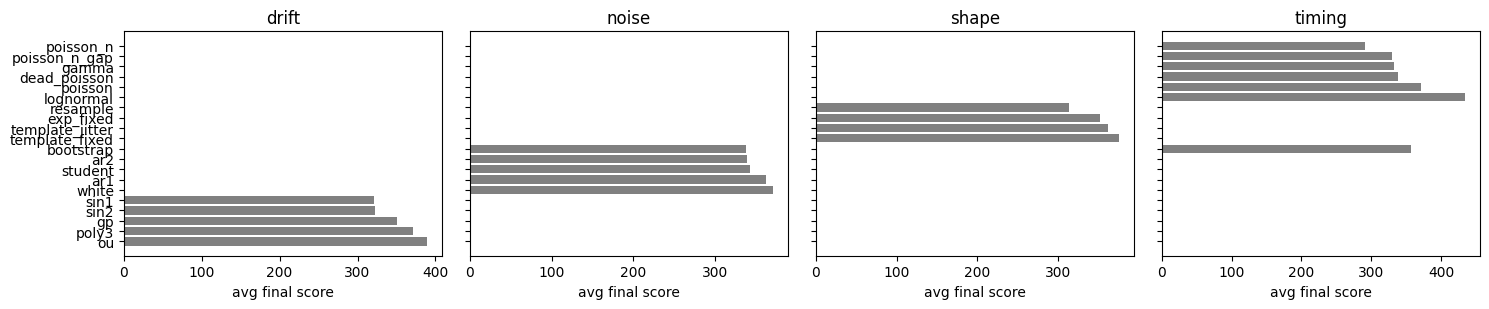

Per-part winner combination: {'drift': 'sin1', 'noise': 'white', 'shape': 'exp_fixed', 'timing': 'poisson_n_gap'} -> position 364 of 700 in the full ranking
Share of all combinations that are as good or better than the winner on each score (small = winner is among the best):
           m_rate m_isi m_amp m_sigma m_acf m_drift m_w1
A (7-10 s)    82%   71%   29%     55%   87%     20%  42%
B (0-10 s)    11%   57%   96%     95%   29%     40%  24%


In [ ]:
comb = dfA[KEYS + ["mean_rank"]].merge(dfB[KEYS + ["mean_rank"]], on=KEYS, suffixes=("_A", "_B"))
comb["final_score"] = (comb.mean_rank_A + comb.mean_rank_B) / 2
comb = comb.sort_values("final_score").reset_index(drop=True)
print("TOP 10 combinations (lower is better)")
display(comb.head(10).round(1))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for a, key in zip(ax, KEYS):
    g = comb.groupby(key).final_score.mean().sort_values()
    a.barh(g.index[::-1], g.values[::-1], color="0.5"); a.set_title(key); a.set_xlabel("avg final score")
plt.tight_layout(); plt.show()
BEST = pd.Series(WIN)
pos = comb.index[(comb[KEYS] == BEST[KEYS]).all(axis=1)][0] + 1
print("Per-part winner combination:", dict(BEST), f"-> position {pos} of {len(comb)} in the full ranking")
mt = [c for c in WEIGHTS]
def pct(df):
    row = df[(df[KEYS] == BEST[KEYS]).all(axis=1)].iloc[0]
    return {c: f"{(df[c] <= row[c]).mean():.0%}" for c in mt}
print("Share of all combinations that are as good or better than the winner on each score (small = winner is among the best):")
print(pd.DataFrame({"A (7-10 s)": pct(dfA), "B (0-10 s)": pct(dfB)}).T.to_string())

## 16. Is the winner stable? (optional, set `RUN_STABILITY = False` to skip)

Generated data is random, so the ranking could change from run to run. Here experiment A is repeated with different random seeds. The table shows how often each option appears among the best 10% of combinations. Options that appear in (almost) every run are reliable.

In [ ]:
if RUN_STABILITY:
    tops = []
    for s in STABILITY_SEEDS:
        df_s, _ = run_experiment(7.0, (7.0, 10.0), s, label=f"seed {s}")
        tops.append(df_s.head(max(1, len(df_s)//10)))
    tops.append(dfA.head(max(1, len(dfA)//10)))
    allt = pd.concat(tops)
    for key in KEYS:
        print(f"\n{key}: share of top-10% combinations")
        print((allt[key].value_counts(normalize=True)).round(2).to_string())
else:
    print("skipped")

seed 11: 700 combinations scored in 38 s
seed 22: 700 combinations scored in 50 s

drift: share of top-10% combinations
drift
sin1     0.44
sin2     0.26
gp       0.16
poly3    0.09
ou       0.06

noise: share of top-10% combinations
noise
ar2          0.33
student      0.28
ar1          0.22
white        0.11
bootstrap    0.05

shape: share of top-10% combinations
shape
exp_fixed          0.36
template_fixed     0.29
resample           0.22
template_jitter    0.13

timing: share of top-10% combinations
timing
poisson_n        0.31
gamma            0.21
bootstrap        0.14
dead_poisson     0.14
poisson          0.11
poisson_n_gap    0.09


## 17. Refit the winner on all 10 s and write down the formula

The best combination is refitted on the whole recording. The formula below is the final answer: it has the fitted numbers filled in.

In [ ]:
fin = fit_all(raw)
FINAL = dict(drift=fin["drift"][BEST["drift"]], noise=fin["noise"][BEST["noise"]],
             shape=fin["shape"][BEST["shape"]], timing=fin["timing"][BEST["timing"]])
FIT_RATE = FINAL["timing"]["rate"]

print("FINAL MODEL:  signal(t) = drift(t) + sum_i spike(t - t_i) + noise(t)\n")
print("1) DRIFT   [%s]  %s\n" % (BEST["drift"],  FINAL["drift"]["formula"]))
print("2) SPIKE TIMES t_i  [%s]  %s   (average rate %.2f Hz)\n" % (BEST["timing"], FINAL["timing"]["formula"], FIT_RATE))
print("3) SPIKE SHAPE  [%s]  %s\n" % (BEST["shape"], FINAL["shape"]["formula"]))
print("4) NOISE   [%s]  %s" % (BEST["noise"], FINAL["noise"]["formula"]))

FINAL MODEL:  signal(t) = drift(t) + sum_i spike(t - t_i) + noise(t)

1) DRIFT   [sin1]  drift(t) = 0.0223 + 0.651*sin(2*pi*0.0899*t + 0.32)   (period 11.1 s)

2) SPIKE TIMES t_i  [poisson_n_gap]  exactly round(4.20 * duration) spikes placed uniformly at random, at least 9.9 ms apart (shortest observed gap is 11 ms)   (average rate 4.20 Hz)

3) SPIKE SHAPE  [exp_fixed]  spike(t) = 4.96 * exp(-(t - t_i)/2.86 ms) for t >= t_i, else 0   (same height for every spike)

4) NOISE   [white]  noise ~ Normal(0, 0.293^2), independent samples


## 18. The generator

`generate_signal(duration_s, seed, rate_hz)` returns a time axis and a realistic voltage trace of any length.

* `duration_s`: length in seconds (can be longer than 10 s).
* `seed`: same seed = same signal.
* `rate_hz`: optional. If given, the spike rate is changed to this value, otherwise the fitted rate is used.

In [ ]:
def generate_signal(duration_s=10.0, seed=0, rate_hz=None):
    scale = 1.0 if rate_hz is None else FIT_RATE / rate_hz
    g = generate(FINAL, duration_s, np.random.default_rng(seed), rate_scale=scale)
    return g["t"], g["raw"], g["times"]

t_new, x_new, spk_times = generate_signal(10, seed=1)
det_new = detect(x_new)
print("generated 10 s: spikes =", len(det_new["cross"]), "| real =", len(real_det["cross"]))

generated 10 s: spikes = 42 | real = 42


## 18b. Reconstruct the real 10 s

If the model is right, then **drift + spikes at the real spike times** should explain the real recording completely, and what is left over should be pure noise (white, normal, standard deviation 0.3). This is the strongest test of the drift and the spike shape, because it does not depend on random spike times.

variance of the real data explained by drift + spikes: 83.4%
left over: sd = 0.299, skew = 0.02, excess kurtosis = -0.04, autocorrelation lag 1 = -0.017


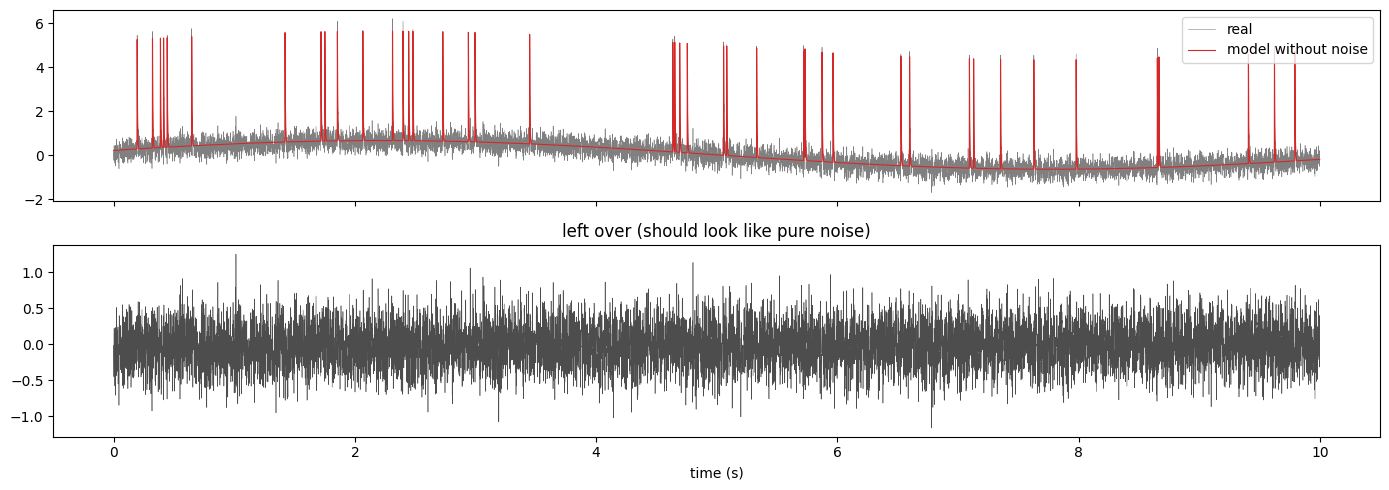

In [ ]:
g_rec = generate(FINAL, 10, np.random.default_rng(0), spike_times=real_det["cross"] / FS)
determ = g_rec["drift"] + g_rec["spikes"]                 # model without noise
left = raw - determ
print(f"variance of the real data explained by drift + spikes: {1 - left.var() / raw.var():.1%}")
print(f"left over: sd = {left.std():.3f}, skew = {stats.skew(left):.2f}, excess kurtosis = {stats.kurtosis(left):.2f}, autocorrelation lag 1 = {np.corrcoef(left[:-1], left[1:])[0,1]:.3f}")
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax[0].plot(t_all, raw, lw=.4, color="0.5", label="real"); ax[0].plot(t_all, determ, lw=.8, color="tab:red", label="model without noise"); ax[0].legend(loc="upper right")
ax[1].plot(t_all, left, lw=.4, color="0.3"); ax[1].set_title("left over (should look like pure noise)"); ax[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## 19. Does the generated data look like the real data?

Left column: real data. Right column: one generated signal with the same detector applied. Below: the statistics compared over 30 generated signals against the real recording (mean +- spread over the 30 signals). If the real value sits inside the generated spread, the model reproduces that property.

,real,generated mean,generated sd,real inside mean +- 2 sd
spikes,42.000,42.000,0.000,True
rate_hz,4.200,4.200,0.000,True
noise_sigma,0.307,0.302,0.003,True
mean_peak,4.950,4.907,0.059,True
min_isi_ms,11.000,13.600,3.747,True
median_isi_ms,169.000,160.333,28.748,True
baseline_range,1.554,1.501,0.056,True
acf_lag1,-0.010,0.003,0.010,True


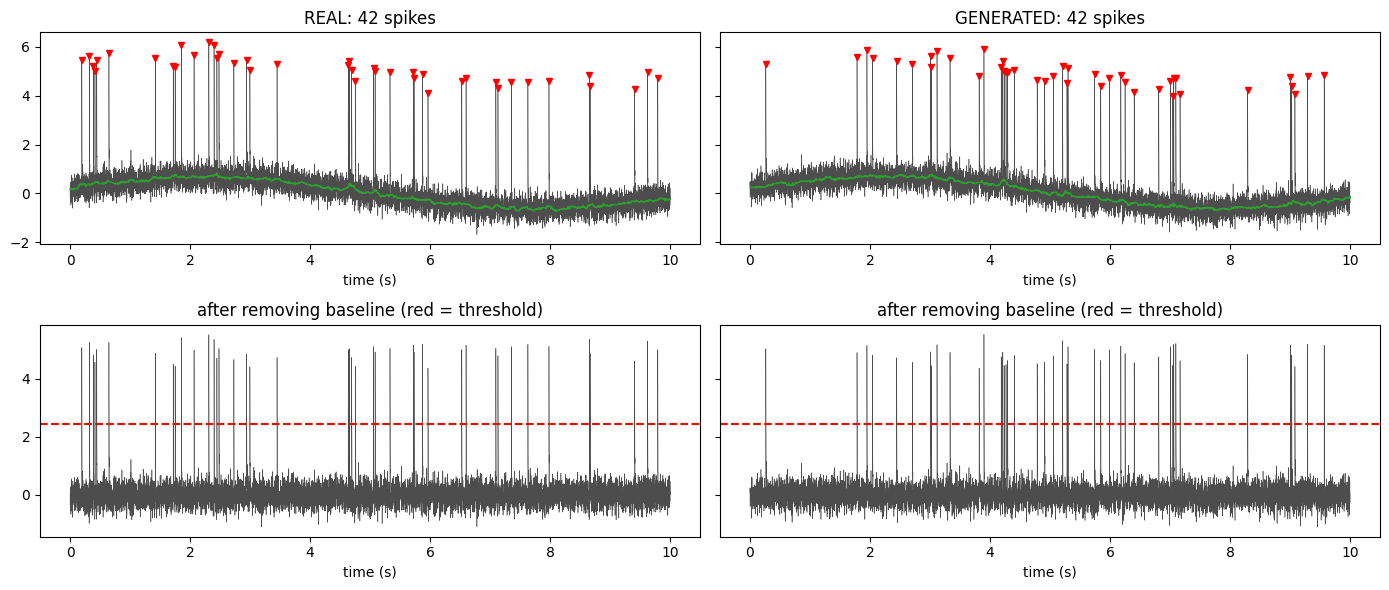

In [ ]:
def summary(x):
    d = detect(x); s = win_stats(d, 0, len(x))
    return dict(spikes=s["n"], rate_hz=s["n"] / (len(x)/FS), noise_sigma=s["sigma"], mean_peak=s["amp"].mean() if len(s["amp"]) else np.nan,
                min_isi_ms=s["isi"].min()*1000 if len(s["isi"]) else np.nan, median_isi_ms=np.median(s["isi"])*1000 if len(s["isi"]) else np.nan,
                baseline_range=d["base"].max() - d["base"].min(), acf_lag1=s["acf"][0])

gens = pd.DataFrame([summary(generate_signal(10, seed=100 + i)[1]) for i in range(30)])
real_row = pd.Series(summary(raw))
tab = pd.DataFrame({"real": real_row, "generated mean": gens.mean(), "generated sd": gens.std(),
                    "real inside mean +- 2 sd": pd.Series({k: bool(abs(real_row[k] - gens[k].mean()) <= 2 * gens[k].std()) for k in gens.columns})})
display(tab.round(3))

fig, ax = plt.subplots(2, 2, figsize=(14, 6), sharey="row")
for col, (xx, tt, dd, ttl) in enumerate([(raw, t_all, real_det, "REAL"), (x_new, t_new, det_new, "GENERATED")]):
    ax[0, col].plot(tt, xx, lw=.4, color="0.3"); ax[0, col].plot(tt, dd["base"], color="tab:green", lw=1)
    ax[0, col].plot(tt[dd["peaks"]], xx[dd["peaks"]], "rv", ms=4)
    ax[0, col].set_title(f"{ttl}: {len(dd['cross'])} spikes"); ax[0, col].set_xlabel("time (s)")
    ax[1, col].plot(tt, dd["y"], lw=.4, color="0.3"); ax[1, col].axhline(K_THR*dd["sigma"], color="r", ls="--")
    ax[1, col].set_title("after removing baseline (red = threshold)"); ax[1, col].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

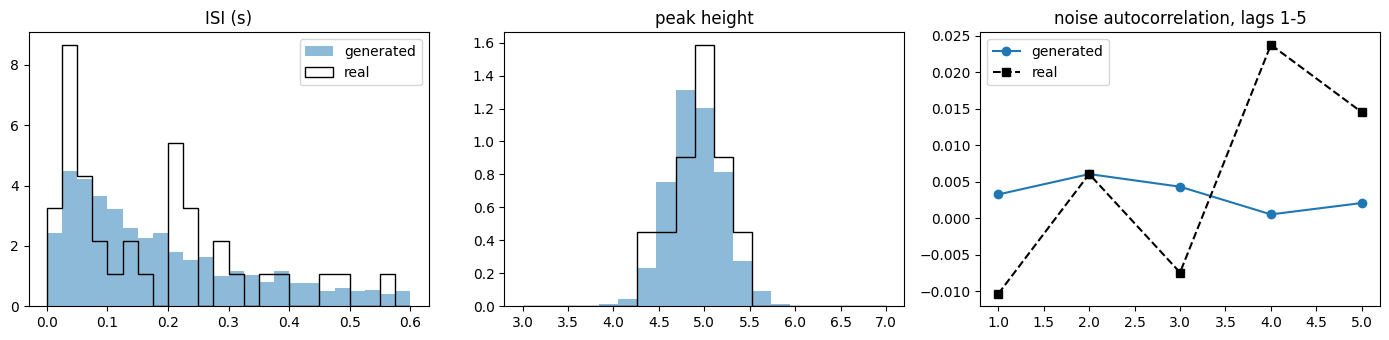

In [ ]:
# distributions: ISI, peak height, noise autocorrelation (real vs 30 generated signals)
isi_g, amp_g, acf_g = [], [], []
for i in range(30):
    d = detect(generate_signal(10, seed=100 + i)[1]); s = win_stats(d, 0, 10000)
    isi_g.append(s["isi"]); amp_g.append(s["amp"]); acf_g.append(s["acf"])
rs = win_stats(real_det, 0, 10000)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
bins = np.linspace(0, 0.6, 25)
ax[0].hist(np.concatenate(isi_g), bins, density=True, alpha=.5, label="generated"); ax[0].hist(rs["isi"], bins, density=True, histtype="step", color="k", label="real")
ax[0].set_title("ISI (s)"); ax[0].legend()
bins = np.linspace(3, 7, 20)
ax[1].hist(np.concatenate(amp_g), bins, density=True, alpha=.5); ax[1].hist(rs["amp"], bins, density=True, histtype="step", color="k"); ax[1].set_title("peak height")
ax[2].plot(range(1, 6), np.mean(acf_g, 0), "o-", label="generated"); ax[2].plot(range(1, 6), rs["acf"], "ks--", label="real"); ax[2].set_title("noise autocorrelation, lags 1-5"); ax[2].legend()
plt.tight_layout(); plt.show()

## 20. Generate beyond 10 s, then save the model

Here the model produces 60 s of data (more than the 10 s it was fitted on). We check that the firing rate and noise stay close to the fitted values. Note: past 10 s the drift is a model prediction, not a measurement, so it is the least certain part (see the notes in section 5).

The last cell saves the winning model (names and fitted numbers) to `final_model.json`, and the generated 60 s to `generated_60s.npz`. In Colab they are downloaded.

60 s generated: 252 spikes -> 4.20 Hz (fitted rate 4.20 Hz), noise sigma 0.301 (real 0.307)


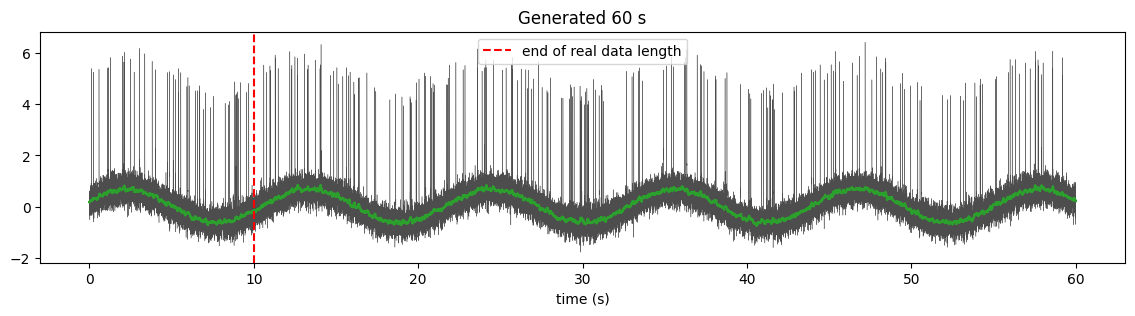

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved final_model.json and generated_60s.npz


In [ ]:
t_long, x_long, _ = generate_signal(60, seed=7)
dl = detect(x_long)
print(f"60 s generated: {len(dl['cross'])} spikes -> {len(dl['cross'])/60:.2f} Hz (fitted rate {FIT_RATE:.2f} Hz), noise sigma {dl['sigma']:.3f} (real {real_det['sigma']:.3f})")
plt.figure(figsize=(14, 3)); plt.plot(t_long, x_long, lw=.3, color="0.3"); plt.plot(t_long, dl["base"], color="tab:green")
plt.axvline(10, color="r", ls="--", label="end of real data length"); plt.legend(); plt.xlabel("time (s)"); plt.title("Generated 60 s"); plt.show()

out = dict(best=dict(BEST[KEYS]), fitted_rate_hz=FIT_RATE,
           detector=dict(k=K_THR, dead_ms=DEAD_MS, peak_ms=PEAK_MS, baseline_window=BASE_WIN),
           formulas={k: FINAL[k]["formula"] for k in FINAL},
           parameters={k: FINAL[k]["params"] for k in FINAL},
           top10=comb.head(10).round(2).to_dict("records"))
json.dump(out, open("final_model.json", "w"), indent=2, default=float)
np.savez("generated_60s.npz", t=t_long, raw_data=x_long)
if IN_COLAB:
    files.download("final_model.json"); files.download("generated_60s.npz")
print("saved final_model.json and generated_60s.npz")

## How to read the result

* **Section 14** shows the best combination and which part of the model matters most.
* **Section 15** tells you whether that choice is stable or just luck.
* **Section 16** is the final formula with numbers.
* **Section 18** is the check that generated data matches the real data.

**Limits.** The noise and spikes are random, so the generated data can match the real data only in statistics (rate, spike shape, noise, drift range), never sample by sample. The drift beyond 10 s is a prediction. With only about 42 spikes the timing model is not tightly constrained, so a different model may fit equally well.